# 01 - Probe-parameter sweep of the linearized-ptychography Jacobian modes

A naive two-parameter sweep: **defocus** x **convergence semiangle**. For every probe
setting we build the local intensity Jacobian at one scan position and extract its
leading object-space modes.

## What a mode is here

The object is perturbed in phase, $O_1 = O_0 e^{ih}$ with $h$ real, and the linearized
change in detector intensity at scan position $R$ is

$$A_R h = -2\,\mathrm{Im}\!\left[\overline{\Psi_{0,R}}\;\mathrm{crop}\,\mathcal{F}\{\psi_{0,R}\,h\}\right],
\qquad \psi_{0,R}=P_R O_0,\quad \Psi_{0,R}=\mathrm{crop}\,\mathcal{F}\{\psi_{0,R}\}.$$

Take the SVD $A_R = U\Sigma V^{\mathsf T}$. The columns of $V$ are **real phase
perturbations in object space**; mode $i$ produces a detector response of norm
$\sigma_i$ per unit norm of perturbation. So $v_1$ is the perturbation this probe sees
*best*, and a mode whose $\sigma$ has collapsed is one the probe is effectively blind to.
The ratio $\sigma_4/\sigma_1$ says how quickly that sensitivity runs out - how many
independent things the probe can distinguish before the measurement stops responding.

Nothing here depends on the perturbation that notebook 00 used; $A_R$ is a property of
the **probe and the base object only**, so this sweep is about the instrument setting.

## Two things to keep in mind when reading the figure

* **The leading singular values come in near-degenerate pairs** for a centro-symmetric
  probe. Within a degenerate pair the individual vectors are not defined - only their
  joint subspace is - so the orientation you see inside a pair is set by the random
  seed. Every panel prints its $\sigma_i$; where two are equal to the digits shown,
  read the pair, not the member.
* This is **one scan position**, not the full ptychographic Jacobian. The modes are
  therefore localized under the probe, and a defocused probe spreads them out. That is
  the effect the sweep is built to show.

In [1]:
import sys
import pickle
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import linearized_jacobian as lj

print("notebook dir :", NOTEBOOK_DIR)
print("module       :", lj.__file__)

/home/rotem/ptycho_light/.ptycho_light_venv/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


notebook dir : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho
module       : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/linearized_jacobian.py


## Configuration

The only cell to edit per experiment.

In [2]:
PHASE_CACHE_PATH = NOTEBOOK_DIR.parent / "bcenters_base_excited_phases_wide_fov.pkl"
PHASE_CACHE_KEY_BASE = "base"

ACC_VOLTAGE_EV = 60e3
SLICE_THICKNESS_ANG = 1.0          # bookkeeping slice for a projected phase object

# DEFOCUS_SWEEP_ANG = [0.0, 25.0, 50.0, 100.0]        # rows of the outer 4x4
DEFOCUS_SWEEP_ANG = [0.0, 50.0, 100.0, 200.0]        # rows of the outer 4x4
SEMIANGLE_SWEEP_MRAD = [40.0, 30.0, 20.0, 10.0]     # columns of the outer 4x4

N_MODES_SHOWN = 4                  # the 2x2 inside each outer panel
PROBE_POSITION_FRACTION = (0.5, 0.5)   # where in the field of view to sit the probe
MODE_VIEW_HALFWIDTH_ANG = 6.0      # mode-panel half-width [A]; None = full field of view
RANDOM_SEED = 0                    # fixes the orientation chosen inside degenerate pairs

SERIES_COLORS_BY_DEFOCUS = ["#0072B2", "#E69F00", "#009E73", "#D55E00"]  # Okabe-Ito, CVD-checked
SERIES_STYLES_BY_SEMIANGLE = ["-", "--", "-.", ":"]

print("defocus sweep [Angstrom]  :", DEFOCUS_SWEEP_ANG)
print("semiangle sweep [mrad]    :", SEMIANGLE_SWEEP_MRAD)
print("configurations            :", len(DEFOCUS_SWEEP_ANG) * len(SEMIANGLE_SWEEP_MRAD))

defocus sweep [Angstrom]  : [0.0, 50.0, 100.0, 200.0]
semiangle sweep [mrad]    : [40.0, 30.0, 20.0, 10.0]
configurations            : 16


## Load the base object and set up the grid

Only the **base** phase is needed - the Jacobian does not involve the perturbation.

In [3]:
with open(PHASE_CACHE_PATH, "rb") as handle:
    phase_cache = pickle.load(handle)

phase_base = np.asarray(phase_cache[PHASE_CACHE_KEY_BASE], dtype=np.float32)
object_x_ang = np.asarray(phase_cache["x"], dtype=np.float32)
object_y_ang = np.asarray(phase_cache["y"], dtype=np.float32)
object_sampling_ang = (
    float(object_y_ang[1] - object_y_ang[0]),
    float(object_x_ang[1] - object_x_ang[0]),
)
object_base = np.exp(1j * phase_base).astype(np.complex64)

potential = lj.make_phase_potential(
    phase_base, ACC_VOLTAGE_EV, SLICE_THICKNESS_ANG, object_sampling_ang
)
field_of_view_ang = tuple(float(v) for v in potential.extent)

# Probe position: abTEM measures from the array corner, the cached axes are centred on
# the defect, so carry both and plot in the object frame.
probe_position_abtem_ang = (
    PROBE_POSITION_FRACTION[0] * field_of_view_ang[0],
    PROBE_POSITION_FRACTION[1] * field_of_view_ang[1],
)
probe_position_object_ang = (
    float(object_x_ang[0]) + probe_position_abtem_ang[0],
    float(object_y_ang[0]) + probe_position_abtem_ang[1],
)
object_extent_ang = [
    float(object_x_ang[0]), float(object_x_ang[-1]),
    float(object_y_ang[0]), float(object_y_ang[-1]),
]

reference_probe = lj.make_probe(
    ACC_VOLTAGE_EV, SEMIANGLE_SWEEP_MRAD[-1], DEFOCUS_SWEEP_ANG[0], potential
)
detector_shape = lj.valid_detector_shape(reference_probe)
electron_wavelength_ang = float(reference_probe.wavelength)

print("object grid               :", phase_base.shape)
print("object sampling [A/px]    :", object_sampling_ang)
print("field of view [A]         :", field_of_view_ang)
print("probe position (object) [A]:", probe_position_object_ang)
print("detector shape (valid)    :", detector_shape)
print("wavelength [A]            :", electron_wavelength_ang)
print()
print("geometric probe diameter 2*alpha*|df| [A] -- compare against the field of view:")
for defocus_ang in DEFOCUS_SWEEP_ANG:
    diameters = [2 * semiangle_mrad * 1e-3 * abs(defocus_ang)
                 for semiangle_mrad in SEMIANGLE_SWEEP_MRAD]
    print(f"  defocus {defocus_ang:6.1f} A : " +
          "  ".join(f"{d:5.2f}" for d in diameters))

object grid               : (251, 251)
object sampling [A/px]    : (0.09599971771240234, 0.09599971771240234)
field of view [A]         : (24.09592914581299, 24.09592914581299)
probe position (object) [A]: (0.04796457290649414, 0.04796457290649414)
detector shape (valid)    : (119, 119)
wavelength [A]            : 0.04866060479040298

geometric probe diameter 2*alpha*|df| [A] -- compare against the field of view:
  defocus    0.0 A :  0.00   0.00   0.00   0.00
  defocus   50.0 A :  4.00   3.00   2.00   1.00
  defocus  100.0 A :  8.00   6.00   4.00   2.00
  defocus  200.0 A : 16.00  12.00   8.00   4.00


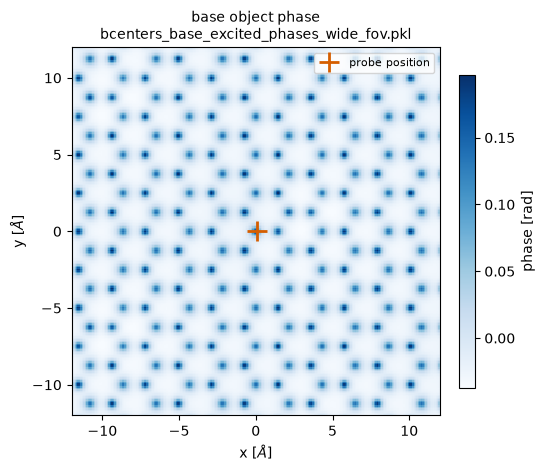

In [ ]:
fig, ax = plt.subplots(figsize=(5.4, 4.6), constrained_layout=True)
image = ax.imshow(
    phase_base, extent=object_extent_ang, origin="lower",
    cmap="Blues", interpolation="nearest",
)
ax.plot(*probe_position_object_ang, marker="+", color="#D55E00", markersize=14,
        markeredgewidth=2.0, linestyle="none", label="probe position")
ax.set_xlabel("x [$\\AA$]")
ax.set_ylabel("y [$\\AA$]")
ax.set_title(f"base object phase\n{PHASE_CACHE_PATH.name}", fontsize=10)
ax.legend(loc="upper right", frameon=True, fontsize=8)
fig.colorbar(image, ax=ax, shrink=0.85, label="phase [rad]")
plt.show()

## The sweep

For each (defocus, semiangle): build the probe, form the exit wave and the base camera
wave, and run the matrix-free randomized subspace iteration for the leading modes. The
dense Jacobian is never assembled, so this runs on the CPU in seconds and leaves the
GPU free.

In [5]:
sweep_shape = (len(DEFOCUS_SWEEP_ANG), len(SEMIANGLE_SWEEP_MRAD))
probe_amplitude_by_config = np.empty(sweep_shape, dtype=object)
object_modes_by_config = np.empty(sweep_shape, dtype=object)
singular_values_by_config = np.zeros((*sweep_shape, N_MODES_SHOWN), dtype=np.float32)

start_time = time.time()
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        probe = lj.make_probe(ACC_VOLTAGE_EV, semiangle_mrad, defocus_ang, potential)
        probe_realspace = np.asarray(
            probe.build(scan=list(probe_position_abtem_ang)).compute().array
        ).astype(np.complex64)
        exit_wave = (probe_realspace * object_base).astype(np.complex64)
        camera_wave_base = lj.camera_wave_from_exit_wave(exit_wave, detector_shape)

        object_modes, singular_values = lj.leading_jacobian_object_modes(
            exit_wave, camera_wave_base, detector_shape,
            n_modes=N_MODES_SHOWN, seed=RANDOM_SEED,
        )

        probe_amplitude_by_config[row, col] = np.abs(probe_realspace)
        object_modes_by_config[row, col] = object_modes
        singular_values_by_config[row, col] = singular_values

    print(f"defocus {defocus_ang:6.1f} A done   ({time.time() - start_time:5.1f} s)")

print(f"\nsweep complete: {sweep_shape[0] * sweep_shape[1]} configurations "
      f"in {time.time() - start_time:.1f} s")

defocus    0.0 A done   (  4.9 s)
defocus   50.0 A done   (  9.9 s)
defocus  100.0 A done   ( 14.8 s)
defocus  200.0 A done   ( 19.9 s)

sweep complete: 16 configurations in 19.9 s


### Does the display window clip any mode?

The modes are localized under the probe, so the mode figure zooms in. That zoom is only
honest if it contains the modes, so measure the radius holding 99% of the mode power for
every configuration rather than assuming it.

In [6]:
row_index, col_index = np.mgrid[0:phase_base.shape[0], 0:phase_base.shape[1]]
radius_from_probe_ang = np.hypot(
    (row_index - (probe_position_object_ang[1] - object_y_ang[0]) / object_sampling_ang[0]),
    (col_index - (probe_position_object_ang[0] - object_x_ang[0]) / object_sampling_ang[1]),
) * object_sampling_ang[0]
radial_order = np.argsort(radius_from_probe_ang.ravel())
sorted_radius_ang = radius_from_probe_ang.ravel()[radial_order]

mode_radius99_ang = np.zeros(sweep_shape, dtype=np.float32)
for row in range(sweep_shape[0]):
    for col in range(sweep_shape[1]):
        mode_power = (object_modes_by_config[row, col] ** 2).sum(axis=0)
        cumulative = np.cumsum(mode_power.ravel()[radial_order])
        cumulative /= cumulative[-1]
        mode_radius99_ang[row, col] = sorted_radius_ang[np.searchsorted(cumulative, 0.99)]

window_halfwidth_ang = (field_of_view_ang[0] / 2 if MODE_VIEW_HALFWIDTH_ANG is None
                        else MODE_VIEW_HALFWIDTH_ANG)
print("radius holding 99% of the mode power [A], rows = defocus, cols = semiangle:")
print(f"{'':>12}" + "".join(f"{s:>9.0f}" for s in SEMIANGLE_SWEEP_MRAD) + "   mrad")
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    print(f"{defocus_ang:9.0f} A " + "".join(f"{v:9.2f}" for v in mode_radius99_ang[row]))
print(f"\nlargest r99 = {mode_radius99_ang.max():.2f} A   display half-width = "
      f"{window_halfwidth_ang:.2f} A")
if mode_radius99_ang.max() > window_halfwidth_ang:
    print("WARNING: the display window clips at least one mode -- raise "
          "MODE_VIEW_HALFWIDTH_ANG")
else:
    print("OK: every mode is fully inside the displayed window")

radius holding 99% of the mode power [A], rows = defocus, cols = semiangle:
                   40       30       20       10   mrad
        0 A      1.22     1.65     2.47     4.96
       50 A      2.16     1.58     2.05     4.97
      100 A      3.61     3.13     2.26     4.82
      200 A      7.25     5.50     4.25     4.10

largest r99 = 7.25 A   display half-width = 6.00 A


## The probe itself, before anything is read off the modes

A mode figure can look structured while the probe behind it is wrong, and no
object-space quantity will say so. Each panel is scaled to its own peak, so this shows
probe **shape**; the peak amplitude is printed on each so the intensity drop with
defocus stays visible.

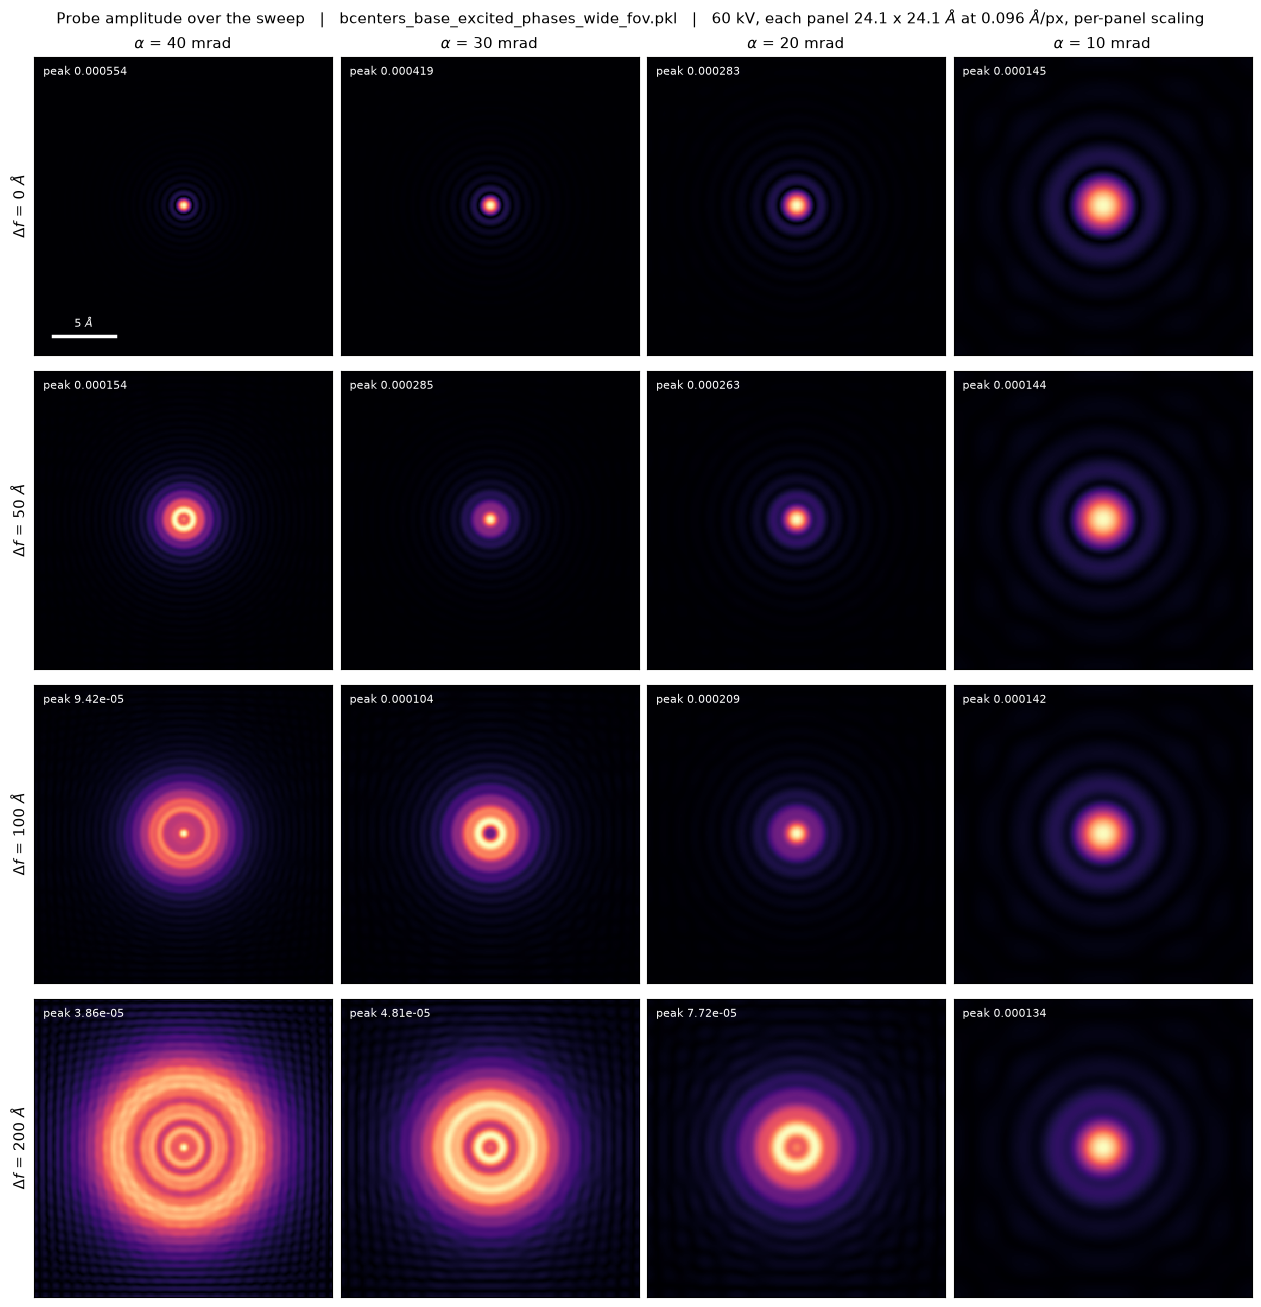

In [7]:
fig, axes = plt.subplots(
    *sweep_shape, figsize=(12.5, 13.0), constrained_layout=True,
    sharex=True, sharey=True,
)
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        ax = axes[row, col]
        amplitude = probe_amplitude_by_config[row, col]
        ax.imshow(
            amplitude, extent=object_extent_ang, origin="lower",
            cmap="magma", vmin=0.0, vmax=float(amplitude.max()),
            interpolation="nearest",
        )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.text(0.03, 0.97, f"peak {amplitude.max():.3g}", transform=ax.transAxes,
                va="top", ha="left", fontsize=8, color="white")
        if row == 0:
            ax.set_title(f"$\\alpha$ = {semiangle_mrad:.0f} mrad", fontsize=11)
        if col == 0:
            ax.set_ylabel(f"$\\Delta f$ = {defocus_ang:.0f} $\\AA$", fontsize=11)

scale_bar_ang = 5.0
axes[0, 0].plot(
    [object_extent_ang[0] + 1.5, object_extent_ang[0] + 1.5 + scale_bar_ang],
    [object_extent_ang[2] + 1.5] * 2, color="white", linewidth=2.5,
)
axes[0, 0].text(object_extent_ang[0] + 1.5 + scale_bar_ang / 2,
                object_extent_ang[2] + 2.0, f"{scale_bar_ang:.0f} $\\AA$",
                color="white", ha="center", va="bottom", fontsize=8)

fig.suptitle(
    f"Probe amplitude over the sweep   |   {PHASE_CACHE_PATH.name}   |   "
    f"{ACC_VOLTAGE_EV/1e3:.0f} kV, each panel {field_of_view_ang[0]:.1f} x "
    f"{field_of_view_ang[1]:.1f} $\\AA$ at {object_sampling_ang[0]:.3f} $\\AA$/px, "
    f"per-panel scaling",
    fontsize=11,
)
plt.show()

## The nested figure

Outer 4x4: one probe configuration per cell, defocus down the rows and semiangle across
the columns. Inner 2x2: the first four object-space modes of that configuration's
Jacobian, ordered $v_1$ top-left, $v_2$ top-right, $v_3$ bottom-left, $v_4$ bottom-right.

Each inner 2x2 shares one symmetric colour scale, so within a cell the panels are
directly comparable - a mode that looks faint really is more spread out. The scale is
**not** shared between cells; each cell prints its own $\sigma_i$, which is the
quantitative comparison across cells.

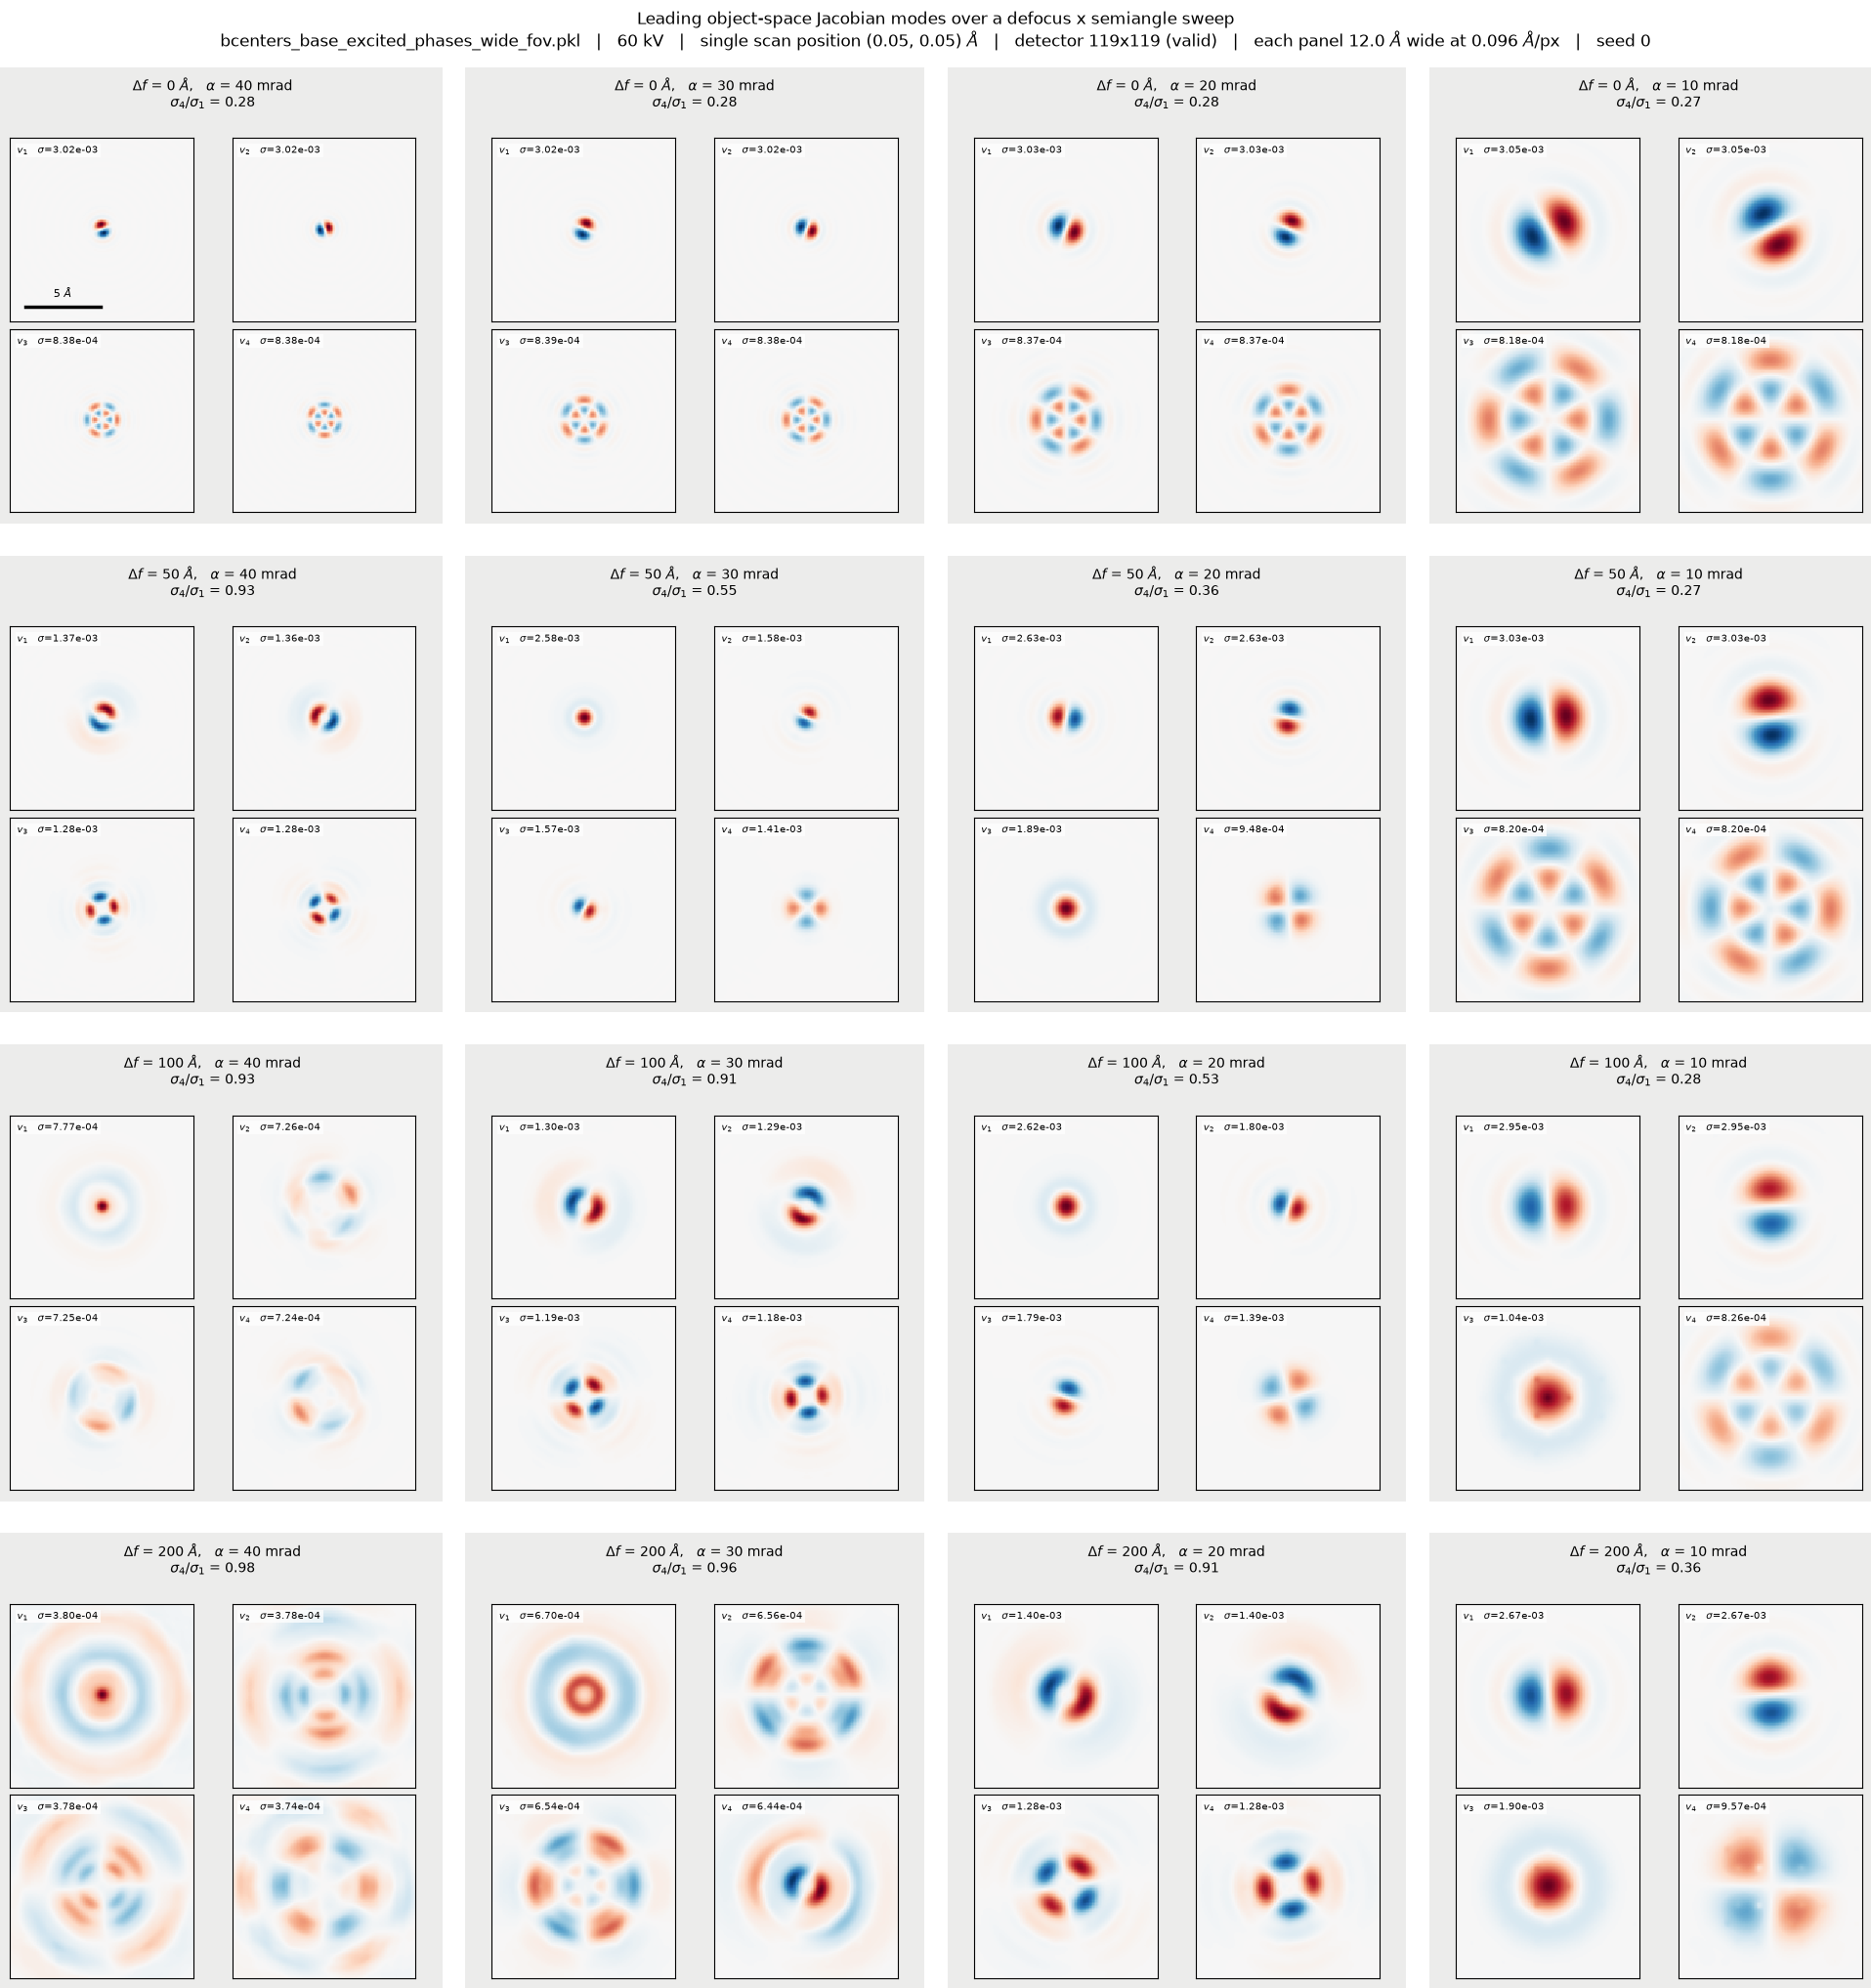

In [8]:
def crop_to_view(image_2d):
    # Optional zoom around the probe, applied identically to every panel.
    if MODE_VIEW_HALFWIDTH_ANG is None:
        return image_2d, object_extent_ang
    half_width_px = int(round(MODE_VIEW_HALFWIDTH_ANG / object_sampling_ang[0]))
    centre_row = int(round((probe_position_object_ang[1] - object_y_ang[0])
                           / object_sampling_ang[0]))
    centre_col = int(round((probe_position_object_ang[0] - object_x_ang[0])
                           / object_sampling_ang[1]))
    row_slice = slice(centre_row - half_width_px, centre_row + half_width_px + 1)
    col_slice = slice(centre_col - half_width_px, centre_col + half_width_px + 1)
    extent = [
        float(object_x_ang[col_slice][0]), float(object_x_ang[col_slice][-1]),
        float(object_y_ang[row_slice][0]), float(object_y_ang[row_slice][-1]),
    ]
    return image_2d[row_slice, col_slice], extent


fig = plt.figure(figsize=(19.5, 20.5))
header_subfigure, body_subfigure = fig.subfigures(2, 1, height_ratios=[1.0, 24.0])
outer_subfigures = body_subfigure.subfigures(*sweep_shape, wspace=0.05, hspace=0.07)

for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        subfigure = outer_subfigures[row, col]
        object_modes = object_modes_by_config[row, col]
        singular_values = singular_values_by_config[row, col]
        shared_vmax = float(np.abs(object_modes).max())

        subfigure.set_facecolor("#ececeb")
        inner_axes = subfigure.subplots(2, 2, gridspec_kw=dict(wspace=0.04, hspace=0.04))
        subfigure.subplots_adjust(left=0.025, right=0.975, top=0.845, bottom=0.025)
        subfigure.suptitle(
            f"$\\Delta f$ = {defocus_ang:.0f} $\\AA$,   "
            f"$\\alpha$ = {semiangle_mrad:.0f} mrad\n"
            f"$\\sigma_4/\\sigma_1$ = {singular_values[3] / singular_values[0]:.2f}",
            fontsize=10,
        )
        for mode_index, ax in enumerate(inner_axes.ravel()):
            mode_image, view_extent = crop_to_view(object_modes[mode_index])
            ax.imshow(
                mode_image, extent=view_extent, origin="lower",
                cmap="RdBu_r", vmin=-shared_vmax, vmax=shared_vmax,
                interpolation="nearest",
            )
            ax.set_xticks([])
            ax.set_yticks([])
            ax.text(
                0.04, 0.96,
                f"$v_{mode_index + 1}$   $\\sigma$={singular_values[mode_index]:.2e}",
                transform=ax.transAxes, va="top", ha="left", fontsize=7.5,
                bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1.2),
            )

scale_bar_ang = 5.0
corner_ax = outer_subfigures[0, 0].axes[0]
corner_extent = corner_ax.get_images()[0].get_extent()
corner_ax.plot(
    [corner_extent[0] + 1.0, corner_extent[0] + 1.0 + scale_bar_ang],
    [corner_extent[2] + 1.0] * 2, color="black", linewidth=2.5,
)
corner_ax.text(corner_extent[0] + 1.0 + scale_bar_ang / 2, corner_extent[2] + 1.4,
               f"{scale_bar_ang:.0f} $\\AA$", ha="center", va="bottom", fontsize=8)

view_width_ang = (field_of_view_ang[0] if MODE_VIEW_HALFWIDTH_ANG is None
                  else 2 * MODE_VIEW_HALFWIDTH_ANG)
header_subfigure.text(
    0.5, 0.45,
    f"Leading object-space Jacobian modes over a defocus x semiangle sweep\n"
    f"{PHASE_CACHE_PATH.name}   |   {ACC_VOLTAGE_EV/1e3:.0f} kV   |   "
    f"single scan position ({probe_position_object_ang[0]:.2f}, "
    f"{probe_position_object_ang[1]:.2f}) $\\AA$   |   "
    f"detector {detector_shape[0]}x{detector_shape[1]} (valid)   |   "
    f"each panel {view_width_ang:.1f} $\\AA$ wide at {object_sampling_ang[0]:.3f} "
    f"$\\AA$/px   |   seed {RANDOM_SEED}",
    ha="center", va="center", fontsize=12,
)
plt.show()

## How fast the sensitivity runs out

$\sigma_1$ is the amplitude of the best-sensed perturbation; $\sigma_4/\sigma_1$ is
how flat the spectrum is, i.e. how many independent perturbations the probe responds to
comparably well. A probe that concentrates all its sensitivity in one mode has a small
ratio; a probe whose sensitivity is spread thin has a ratio near 1.

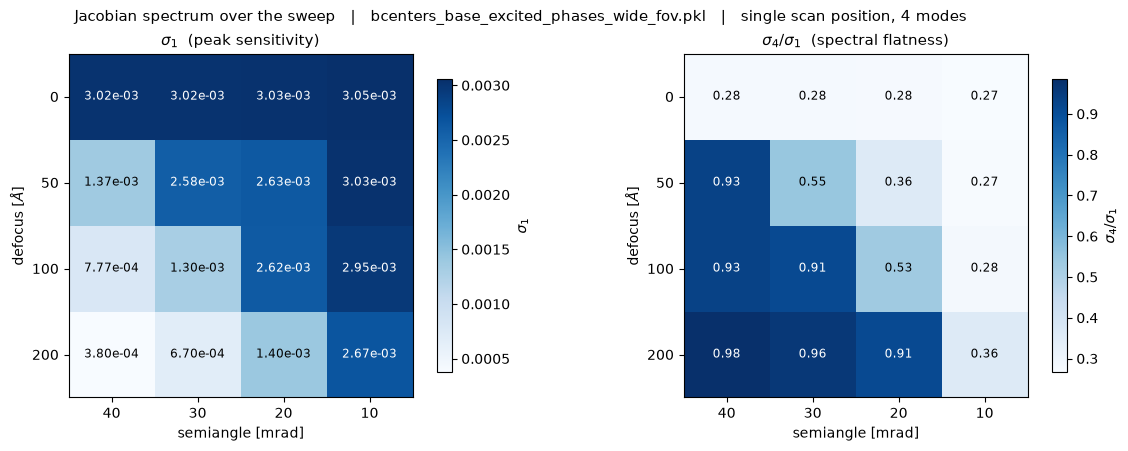

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.4), constrained_layout=True)

for ax, values, title, label, cell_format in [
    (axes[0], singular_values_by_config[..., 0], "$\\sigma_1$  (peak sensitivity)",
     "$\\sigma_1$", "{:.2e}"),
    (axes[1], singular_values_by_config[..., 3] / singular_values_by_config[..., 0],
     "$\\sigma_4/\\sigma_1$  (spectral flatness)", "$\\sigma_4/\\sigma_1$", "{:.2f}"),
]:
    image = ax.imshow(values, cmap="Blues", origin="upper", interpolation="nearest")
    ax.set_xticks(range(len(SEMIANGLE_SWEEP_MRAD)),
                  [f"{s:.0f}" for s in SEMIANGLE_SWEEP_MRAD])
    ax.set_yticks(range(len(DEFOCUS_SWEEP_ANG)),
                  [f"{d:.0f}" for d in DEFOCUS_SWEEP_ANG])
    ax.set_xlabel("semiangle [mrad]")
    ax.set_ylabel("defocus [$\\AA$]")
    ax.set_title(title, fontsize=11)
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            normalized = ((values[row, col] - values.min())
                          / max(float(np.ptp(values)), np.finfo(np.float32).eps))
            ax.text(col, row, cell_format.format(values[row, col]),
                    ha="center", va="center", fontsize=8.5,
                    color="white" if normalized > 0.6 else "black")
    fig.colorbar(image, ax=ax, shrink=0.85, label=label)

# ax = axes[2]
# mode_indices = np.arange(1, N_MODES_SHOWN + 1)
# for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
#     for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
#         spectrum = singular_values_by_config[row, col]
#         ax.plot(mode_indices, spectrum / spectrum[0],
#                 color=SERIES_COLORS_BY_DEFOCUS[row],
#                 linestyle=SERIES_STYLES_BY_SEMIANGLE[col],
#                 linewidth=2.0, marker="o", markersize=5)
# ax.set_xticks(mode_indices)
# ax.set_xlabel("mode index $i$")
# ax.set_ylabel("$\\sigma_i / \\sigma_1$")
# ax.set_title("normalized spectra, all 16 configurations", fontsize=11)
# ax.grid(True, alpha=0.25, linewidth=0.7)
# ax.set_axisbelow(True)

# defocus_handles = [
#     plt.Line2D([], [], color=SERIES_COLORS_BY_DEFOCUS[row], linewidth=2.0,
#                label=f"$\\Delta f$ = {defocus_ang:.0f} $\\AA$")
#     for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG)
# ]
# semiangle_handles = [
#     plt.Line2D([], [], color="0.35", linestyle=SERIES_STYLES_BY_SEMIANGLE[col],
#                linewidth=2.0, label=f"$\\alpha$ = {semiangle_mrad:.0f} mrad")
#     for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD)
# ]
# first_legend = ax.legend(handles=defocus_handles, loc="upper right", fontsize=8,
#                          frameon=True, title="colour")
# ax.add_artist(first_legend)
# ax.legend(handles=semiangle_handles, loc="lower left", fontsize=8, frameon=True,
#           title="line style")

fig.suptitle(
    f"Jacobian spectrum over the sweep   |   {PHASE_CACHE_PATH.name}   |   "
    f"single scan position, {N_MODES_SHOWN} modes", fontsize=11,
)
plt.show()

## Summary table

In [10]:
print(f"{'defocus [A]':>12} {'semiangle [mrad]':>17} "
      + " ".join(f"{'sigma_' + str(i + 1):>11}" for i in range(N_MODES_SHOWN))
      + f" {'s4/s1':>8} {'2a|df| [A]':>11}")
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        spectrum = singular_values_by_config[row, col]
        geometric_diameter_ang = 2 * semiangle_mrad * 1e-3 * abs(defocus_ang)
        print(f"{defocus_ang:12.0f} {semiangle_mrad:17.0f} "
              + " ".join(f"{value:11.4e}" for value in spectrum)
              + f" {spectrum[3] / spectrum[0]:8.3f} {geometric_diameter_ang:11.2f}")

 defocus [A]  semiangle [mrad]     sigma_1     sigma_2     sigma_3     sigma_4    s4/s1  2a|df| [A]
           0                40  3.0156e-03  3.0154e-03  8.3828e-04  8.3793e-04    0.278        0.00
           0                30  3.0216e-03  3.0213e-03  8.3852e-04  8.3808e-04    0.277        0.00
           0                20  3.0330e-03  3.0328e-03  8.3737e-04  8.3722e-04    0.276        0.00
           0                10  3.0539e-03  3.0538e-03  8.1843e-04  8.1760e-04    0.268        0.00
          50                40  1.3693e-03  1.3644e-03  1.2796e-03  1.2756e-03    0.932        4.00
          50                30  2.5769e-03  1.5793e-03  1.5747e-03  1.4057e-03    0.545        3.00
          50                20  2.6281e-03  2.6260e-03  1.8854e-03  9.4836e-04    0.361        2.00
          50                10  3.0278e-03  3.0274e-03  8.1999e-04  8.1978e-04    0.271        1.00
         100                40  7.7740e-04  7.2623e-04  7.2530e-04  7.2419e-04    0.932        8.00


---

# Differential diffraction over the same sweep

The modes above are a property of the probe and the base object; they never saw the
excitation. This section puts the actual excitation through the same 4x4 grid of probe
settings and asks what the camera would record.

Each outer cell is one probe configuration and holds two panels:

1. **Object plane** - the Hamming-windowed differential phase as the image, the base
   object phase as grey contours, a horizontal reference line through the centre of the
   field of view, and the probe amplitude profile along that line drawn on top in
   yellow-green.
2. **Detector plane** - the residual $\Delta I = I_{\text{excited}} - I_{\text{base}}$ as
   a percentage of the **total** base-state diffracted intensity, so summing the
   magnitude of the map gives the annotated integrated percentage directly.

$\Delta I$ is the exact difference of two forward models, not the linearized $A_R h$.

In [11]:
# Parameters for this section only; everything above is untouched.
PHASE_CACHE_KEY_EXCITED = "excited"
APPLY_HAMMING_TO_EXCITATION = True
DIFFERENTIAL_CONTOUR_PERCENTILE = 92.0      # one base-phase contour level per atom
PROBE_PROFILE_HEIGHT_FRACTION = 0.38        # of the half panel, for the overlaid profile
PROBE_PROFILE_COLOR = "#aacc00"
DETECTOR_VIEW_HALFWIDTH_MRAD = 1.8 * max(SEMIANGLE_SWEEP_MRAD)

# What the residual map is a percentage OF. All three are correct; they differ by what
# sits in the denominator, and by orders of magnitude.
#   "peak"  : dI / max(I0)      -- well behaved everywhere, reads ~1 %
#   "local" : dI / I0 per pixel -- true per-pixel contrast, reads ~20 %, blank where dark
#   "total" : dI / sum(I0)      -- reads ~1e-3 %, but the map then sums to the title
#   "bright_field_mean" : dI / <I0>_BF -- divided by the MEAN of I0 inside the bright
#           field disc only, not over the whole frame. A single scalar per configuration,
#           so there is no per-pixel division and nothing to blank; it reads as "change
#           relative to a typical illuminated pixel". The disc is defined geometrically
#           by the aperture, |q| <= scale * semiangle, so it does not move with defocus.
RESIDUAL_NORMALIZATION = "bright_field_mean"
# dI/I0 diverges as I0 -> 0 at the bright-field edge, and that same edge is where the
# at-focus signal lives, so the floor is a genuine trade rather than a free parameter.
# 1e-2 of peak keeps 99.7 % of the intensity and 84-98 % of |dI| while holding the ratio
# in a readable few-percent range; 1e-3 keeps 98 % of |dI| but lets rim pixels reach 37 %
# and swamp the colour scale. The notebook prints what each choice discards.
RESIDUAL_LOCAL_FLOOR_FRACTION = 1e-2     # of peak I0, below which "local" is left blank
# dI/I0 grows without bound towards the disc edge, so the colour limit comes from a
# percentile of the lit pixels, not their max, or a few rim pixels set the whole scale.
RESIDUAL_LOCAL_COLOR_PERCENTILE = 99.0
BRIGHT_FIELD_RADIUS_SCALE = 1.0          # multiples of the semiangle, for "bright_field_mean"

with open(PHASE_CACHE_PATH, "rb") as handle:
    phase_cache_excited = pickle.load(handle)
phase_excited = np.asarray(phase_cache_excited[PHASE_CACHE_KEY_EXCITED], dtype=np.float32)

excitation_phase_rad = (phase_excited - phase_base).astype(np.float32)
if APPLY_HAMMING_TO_EXCITATION:
    hamming_window = np.outer(
        np.hamming(excitation_phase_rad.shape[0]),
        np.hamming(excitation_phase_rad.shape[1]),
    ).astype(np.float32)
    excitation_phase_rad = (excitation_phase_rad * hamming_window).astype(np.float32)

# Both objects carry the SAME excitation that is plotted, so the two panels agree.
object_excited = np.exp(1j * (phase_base + excitation_phase_rad)).astype(np.complex64)

# Camera axis in mrad: reciprocal sampling is 1/(n dx), and angle = q * wavelength.
detector_sampling_inv_ang = 1.0 / (phase_base.shape[0] * object_sampling_ang[0])
detector_pitch_mrad = detector_sampling_inv_ang * electron_wavelength_ang * 1e3
detector_halfwidth_mrad = (detector_shape[0] // 2) * detector_pitch_mrad
detector_extent_mrad = [-detector_halfwidth_mrad, detector_halfwidth_mrad,
                        -detector_halfwidth_mrad, detector_halfwidth_mrad]
detector_axis_mrad = (np.arange(detector_shape[0]) - detector_shape[0] // 2) * detector_pitch_mrad

print("excitation max |dphi| [rad] :", float(np.abs(excitation_phase_rad).max()))
print("hamming window applied      :", APPLY_HAMMING_TO_EXCITATION)
print("detector pitch [mrad/px]    :", round(detector_pitch_mrad, 4))
print("camera panels shown to      :", f"+/- {DETECTOR_VIEW_HALFWIDTH_MRAD:.0f} mrad")

excitation max |dphi| [rad] : 0.02105947770178318
hamming window applied      : True
detector pitch [mrad/px]    : 2.0195
camera panels shown to      : +/- 72 mrad


In [12]:
base_intensity_by_config = np.empty(sweep_shape, dtype=object)
residual_intensity_by_config = np.empty(sweep_shape, dtype=object)
residual_fraction_percent = np.zeros(sweep_shape, dtype=np.float64)
residual_peak_percent = np.zeros(sweep_shape, dtype=np.float64)

start_time = time.time()
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        probe = lj.make_probe(ACC_VOLTAGE_EV, semiangle_mrad, defocus_ang, potential)
        probe_realspace = np.asarray(
            probe.build(scan=list(probe_position_abtem_ang)).compute().array
        ).astype(np.complex64)

        intensity_base = np.abs(lj.camera_wave_from_exit_wave(
            (probe_realspace * object_base).astype(np.complex64), detector_shape)) ** 2
        intensity_excited = np.abs(lj.camera_wave_from_exit_wave(
            (probe_realspace * object_excited).astype(np.complex64), detector_shape)) ** 2
        residual = (intensity_excited - intensity_base).astype(np.float64)

        base_intensity_by_config[row, col] = intensity_base
        residual_intensity_by_config[row, col] = residual
        residual_fraction_percent[row, col] = (
            100.0 * np.abs(residual).sum() / intensity_base.sum())
        residual_peak_percent[row, col] = (
            100.0 * np.abs(residual).max() / intensity_base.max())
    print(f"defocus {defocus_ang:6.1f} A done   ({time.time() - start_time:5.1f} s)")

print(f"\nresidual as % of total base intensity, rows = defocus, cols = semiangle:")
print(f"{'':>12}" + "".join(f"{s:>9.0f}" for s in SEMIANGLE_SWEEP_MRAD) + "   mrad")
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    print(f"{defocus_ang:9.0f} A " + "".join(f"{v:9.4f}" for v in residual_fraction_percent[row]))

defocus    0.0 A done   (  0.0 s)
defocus   50.0 A done   (  0.1 s)
defocus  100.0 A done   (  0.1 s)
defocus  200.0 A done   (  0.2 s)

residual as % of total base intensity, rows = defocus, cols = semiangle:
                   40       30       20       10   mrad
        0 A    0.1693   0.1957   0.2374   0.2556
       50 A    0.4452   0.6130   0.4565   0.3066
      100 A    0.2982   0.4182   0.6916   0.3760
      200 A    0.1756   0.2770   0.5434   0.5329


In [13]:
# Verify that dI / I0 never divides by zero, rather than trusting that the mask covers it.
print(f"{'defocus':>8} {'semi':>6} {'min divisor used':>18} {'blanked px':>11} "
      f"{'% of I0 blanked':>16} {'% of |dI| blanked':>18} {'max |dI/I0| [%]':>16}")
smallest_divisor_overall = np.inf
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        intensity_base = base_intensity_by_config[row, col]
        residual = residual_intensity_by_config[row, col]
        lit = intensity_base > RESIDUAL_LOCAL_FLOOR_FRACTION * intensity_base.max()

        assert intensity_base.max() > 0, "base intensity is identically zero"
        assert lit.any(), "the floor blanked every pixel"
        smallest_divisor = float(intensity_base[lit].min())
        assert smallest_divisor > 0, "a zero slipped past the mask"
        assert np.isfinite(intensity_base[lit]).all(), "non-finite base intensity"
        smallest_divisor_overall = min(smallest_divisor_overall, smallest_divisor)

        ratio = 100.0 * residual[lit] / intensity_base[lit]
        assert np.isfinite(ratio).all(), "non-finite dI/I0 on a lit pixel"

        print(f"{defocus_ang:8.0f} {semiangle_mrad:6.0f} {smallest_divisor:18.3e} "
              f"{int((~lit).sum()):11d} "
              f"{100 * intensity_base[~lit].sum() / intensity_base.sum():16.4f} "
              f"{100 * np.abs(residual[~lit]).sum() / np.abs(residual).sum():18.4f} "
              f"{np.abs(ratio).max():16.2f}")

print(f"\nsmallest divisor anywhere in the sweep: {smallest_divisor_overall:.3e}")
print(f"the mask is applied BEFORE the division, so the divisor is bounded below by "
      f"{RESIDUAL_LOCAL_FLOOR_FRACTION:.0e} x peak I0 by construction")

# Statistics of the bright-field disc used by the "bright_field_mean" normalisation.
# The denominator is a single scalar per configuration, so no per-pixel division occurs.
detector_radius_mrad = np.hypot(detector_axis_mrad[:, None], detector_axis_mrad[None, :])
print(f"\n{'defocus':>8} {'semi':>6} {'BF px':>7} {'<I0>_BF':>12} {'peak I0':>12} "
      f"{'<I0>_BF / peak':>15} {'max |dI|/<I0>_BF [%]':>21} {'% of |dI| inside BF':>20}")
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        intensity_base = base_intensity_by_config[row, col]
        residual = residual_intensity_by_config[row, col]
        bright_field_mask = detector_radius_mrad <= BRIGHT_FIELD_RADIUS_SCALE * semiangle_mrad
        assert bright_field_mask.any(), "the bright-field disc is empty"
        bright_field_mean = float(intensity_base[bright_field_mask].mean())
        assert bright_field_mean > 0, "mean intensity over the BF disc is not positive"
        print(f"{defocus_ang:8.0f} {semiangle_mrad:6.0f} {int(bright_field_mask.sum()):7d} "
              f"{bright_field_mean:12.4e} {intensity_base.max():12.4e} "
              f"{bright_field_mean / intensity_base.max():15.4f} "
              f"{100 * np.abs(residual).max() / bright_field_mean:21.2f} "
              f"{100 * np.abs(residual[bright_field_mask]).sum() / np.abs(residual).sum():20.2f}")


 defocus   semi   min divisor used  blanked px  % of I0 blanked  % of |dI| blanked  max |dI/I0| [%]
       0     40          2.208e-05       12880           0.2828            15.4889             4.80
       0     30          1.561e-05       13425           0.2581            13.0074             9.35
       0     20          3.492e-05       13821           0.1909             9.1904             7.46
       0     10          1.696e-03       14072           0.2053             3.7995             1.93
      50     40          2.133e-05       12880           0.0776             0.9014             7.09
      50     30          1.663e-05       13422           0.1601             1.6742            12.75
      50     20          4.372e-05       13820           0.1780             4.1543            10.69
      50     10          1.701e-03       14072           0.2056             3.1833             2.41
     100     40          3.078e-05       12880           0.0887             1.3695             5.15


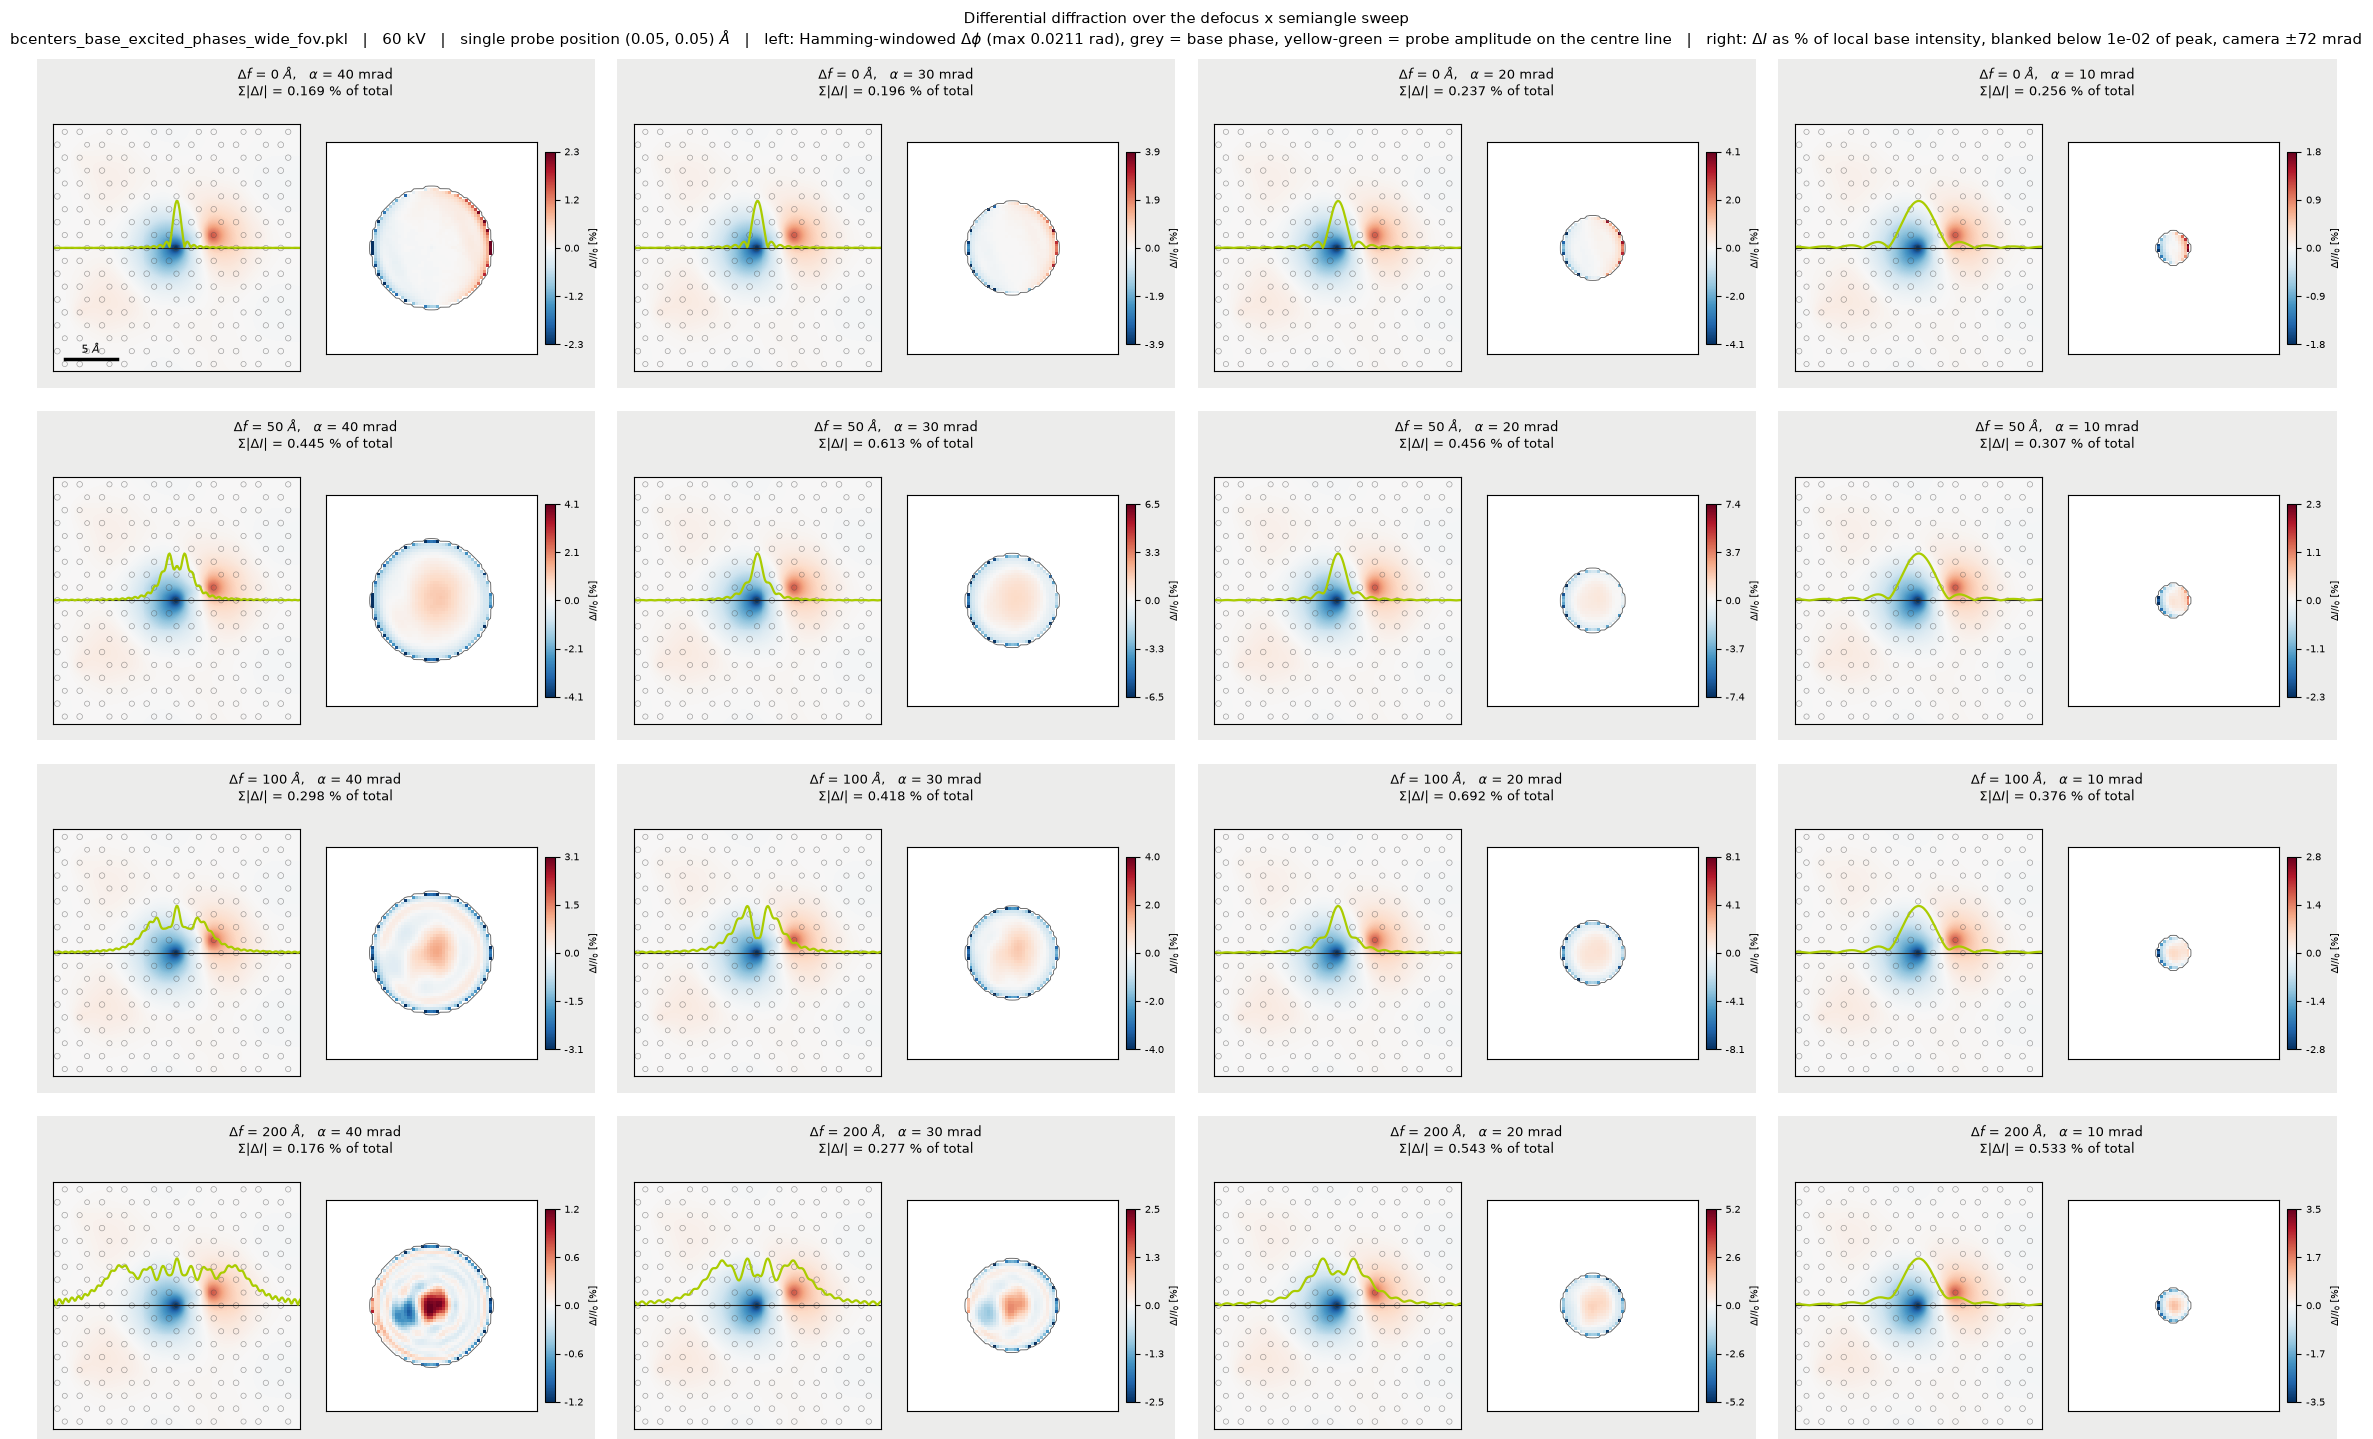

In [14]:
fig = plt.figure(figsize=(23.0, 14.5))
header_subfigure, body_subfigure = fig.subfigures(2, 1, height_ratios=[1.0, 22.0])
outer_subfigures = body_subfigure.subfigures(*sweep_shape, wspace=0.04, hspace=0.07)

base_phase_contour_levels = [np.percentile(phase_base, DIFFERENTIAL_CONTOUR_PERCENTILE)]
excitation_vmax = float(np.abs(excitation_phase_rad).max())
centre_row_index = phase_base.shape[0] // 2
probe_profile_x_ang = object_x_ang
line_y_ang = float(object_y_ang[centre_row_index])
panel_half_height_ang = (object_extent_ang[3] - object_extent_ang[2]) / 2

for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        subfigure = outer_subfigures[row, col]
        subfigure.set_facecolor("#ececeb")
        object_axis, detector_axis = subfigure.subplots(
            1, 2, gridspec_kw=dict(wspace=0.08))
        subfigure.subplots_adjust(left=0.02, right=0.98, top=0.80, bottom=0.05)

        # ---- panel 1: object plane ----
        object_axis.imshow(
            excitation_phase_rad, extent=object_extent_ang, origin="lower",
            cmap="RdBu_r", vmin=-excitation_vmax, vmax=excitation_vmax,
            interpolation="nearest",
        )
        object_axis.contour(
            object_x_ang, object_y_ang, phase_base, levels=base_phase_contour_levels,
            colors="0.30", linewidths=0.45, alpha=0.55,
        )
        object_axis.axhline(line_y_ang, color="0.15", linewidth=0.8, linestyle="-")
        probe_profile = probe_amplitude_by_config[row, col][centre_row_index, :]
        probe_profile_scaled = (
            line_y_ang
            + probe_profile / probe_profile.max()
            * PROBE_PROFILE_HEIGHT_FRACTION * panel_half_height_ang
        )
        object_axis.plot(probe_profile_x_ang, probe_profile_scaled,
                         color=PROBE_PROFILE_COLOR, linewidth=1.6)
        object_axis.set_xlim(object_extent_ang[:2])
        object_axis.set_ylim(object_extent_ang[2:])
        object_axis.set_xticks([])
        object_axis.set_yticks([])

        # ---- panel 2: detector plane ----
        residual = residual_intensity_by_config[row, col]
        intensity_base = base_intensity_by_config[row, col]
        if RESIDUAL_NORMALIZATION == "peak":
            residual_map = 100.0 * residual / intensity_base.max()
            colour_bar_label = "$\\Delta I$ [% of peak $I_0$]"
        elif RESIDUAL_NORMALIZATION == "local":
            lit = intensity_base > RESIDUAL_LOCAL_FLOOR_FRACTION * intensity_base.max()
            residual_map = np.full_like(residual, np.nan)
            residual_map[lit] = 100.0 * residual[lit] / intensity_base[lit]
            colour_bar_label = "$\\Delta I / I_0$ [%]"
        elif RESIDUAL_NORMALIZATION == "bright_field_mean":
            detector_radius_mrad = np.hypot(detector_axis_mrad[:, None],
                                            detector_axis_mrad[None, :])
            bright_field_mask = (detector_radius_mrad
                                 <= BRIGHT_FIELD_RADIUS_SCALE * semiangle_mrad)
            assert bright_field_mask.any(), "the bright-field disc is empty"
            bright_field_mean = float(intensity_base[bright_field_mask].mean())
            assert bright_field_mean > 0, "mean intensity over the BF disc is not positive"
            residual_map = 100.0 * residual / bright_field_mean
            colour_bar_label = "$\\Delta I\\,/\\,\\langle I_0\\rangle_{BF}$ [%]"
        elif RESIDUAL_NORMALIZATION == "total":
            # Carries an explicit 1e-3 factor: per pixel the change is a few times
            # 1e-3 % of the whole pattern, because the total is spread over ~1e4 pixels.
            # In exchange, summing |map| reproduces the integrated % in the title.
            residual_map = 1e3 * 100.0 * residual / intensity_base.sum()
            colour_bar_label = "$\\Delta I$ [$10^{-3}$ % of total]"
        else:
            raise ValueError(f"unknown RESIDUAL_NORMALIZATION: {RESIDUAL_NORMALIZATION}")
        if RESIDUAL_NORMALIZATION == "local":
            limit = float(np.nanpercentile(np.abs(residual_map),
                                           RESIDUAL_LOCAL_COLOR_PERCENTILE))
        else:
            limit = float(np.nanmax(np.abs(residual_map)))
        handle = detector_axis.imshow(
            residual_map, cmap="RdBu_r", vmin=-limit, vmax=limit,
            interpolation="nearest", extent=detector_extent_mrad, origin="lower",
        )
        detector_axis.contour(
            detector_axis_mrad, detector_axis_mrad, intensity_base,
            levels=[0.01 * intensity_base.max()], colors="0.35", linewidths=0.6,
        )
        detector_axis.set_xlim(-DETECTOR_VIEW_HALFWIDTH_MRAD, DETECTOR_VIEW_HALFWIDTH_MRAD)
        detector_axis.set_ylim(-DETECTOR_VIEW_HALFWIDTH_MRAD, DETECTOR_VIEW_HALFWIDTH_MRAD)
        detector_axis.set_xticks([])
        detector_axis.set_yticks([])
        colour_bar = subfigure.colorbar(
            handle, ax=detector_axis, shrink=0.78, pad=0.03, format="%.1f")
        colour_bar.set_label(colour_bar_label, fontsize=7)
        colour_bar.ax.tick_params(labelsize=7)
        colour_bar.set_ticks(np.linspace(-limit, limit, 5))

        subfigure.suptitle(
            f"$\\Delta f$ = {defocus_ang:.0f} $\\AA$,   "
            f"$\\alpha$ = {semiangle_mrad:.0f} mrad\n"
            f"$\\Sigma|\\Delta I|$ = {residual_fraction_percent[row, col]:.3f} % of total",
            fontsize=9.5,
        )

scale_bar_ang = 5.0
corner_axis = outer_subfigures[0, 0].axes[0]
corner_axis.plot(
    [object_extent_ang[0] + 1.2, object_extent_ang[0] + 1.2 + scale_bar_ang],
    [object_extent_ang[2] + 1.2] * 2, color="black", linewidth=2.5,
)
corner_axis.text(object_extent_ang[0] + 1.2 + scale_bar_ang / 2,
                 object_extent_ang[2] + 1.5, f"{scale_bar_ang:.0f} $\\AA$",
                 ha="center", va="bottom", fontsize=8)

header_subfigure.text(
    0.5, 0.45,
    f"Differential diffraction over the defocus x semiangle sweep\n"
    f"{PHASE_CACHE_PATH.name}   |   {ACC_VOLTAGE_EV/1e3:.0f} kV   |   "
    f"single probe position ({probe_position_object_ang[0]:.2f}, "
    f"{probe_position_object_ang[1]:.2f}) $\\AA$   |   left: Hamming-windowed "
    f"$\\Delta\\phi$ (max {excitation_vmax:.4f} rad), grey = base phase, "
    f"yellow-green = probe amplitude on the centre line   |   right: $\\Delta I$ as % of "
    f"{RESIDUAL_NORMALIZATION} base intensity"
    f"{f', blanked below {RESIDUAL_LOCAL_FLOOR_FRACTION:.0e} of peak' if RESIDUAL_NORMALIZATION == 'local' else ''}, camera $\\pm${DETECTOR_VIEW_HALFWIDTH_MRAD:.0f} mrad",
    ha="center", va="center", fontsize=11,
)
plt.show()

In [15]:
print(f"{'defocus [A]':>12} {'semiangle [mrad]':>17} {'sum|dI| [% total]':>19} "
      f"{'peak|dI| [% peak]':>19} {'sigma_1':>11} {'s4/s1':>8}")
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        spectrum = singular_values_by_config[row, col]
        print(f"{defocus_ang:12.0f} {semiangle_mrad:17.0f} "
              f"{residual_fraction_percent[row, col]:19.4f} "
              f"{residual_peak_percent[row, col]:19.3f} "
              f"{spectrum[0]:11.4e} {spectrum[3] / spectrum[0]:8.3f}")

best_row, best_col = np.unravel_index(np.argmax(residual_fraction_percent),
                                      residual_fraction_percent.shape)
print(f"\nlargest residual: defocus {DEFOCUS_SWEEP_ANG[best_row]:.0f} A, "
      f"semiangle {SEMIANGLE_SWEEP_MRAD[best_col]:.0f} mrad "
      f"({residual_fraction_percent[best_row, best_col]:.4f} % of total)")

 defocus [A]  semiangle [mrad]   sum|dI| [% total]   peak|dI| [% peak]     sigma_1    s4/s1
           0                40              0.1693               0.836  3.0156e-03    0.278
           0                30              0.1957               0.820  3.0216e-03    0.277
           0                20              0.2374               0.768  3.0330e-03    0.276
           0                10              0.2556               0.643  3.0539e-03    0.268
          50                40              0.4452               1.246  1.3693e-03    0.932
          50                30              0.6130               1.479  2.5769e-03    0.545
          50                20              0.4565               1.271  2.6281e-03    0.361
          50                10              0.3066               0.769  3.0278e-03    0.271
         100                40              0.2982               1.085  7.7740e-04    0.932
         100                30              0.4182               1.108  1.2964e-

sum(I_0) per pattern      : 0.9999911785125732
shared colour limit |dI|  : 1.5464e-04
largest raw residual at   : defocus 200 A, semiangle 10 mrad


<>:35: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:35: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/tmp/ipykernel_1610312/2844977640.py:35: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  ax.set_title(f"max $|\Delta I|$ = {np.abs(residual).max():.2e}", fontsize=8.5)


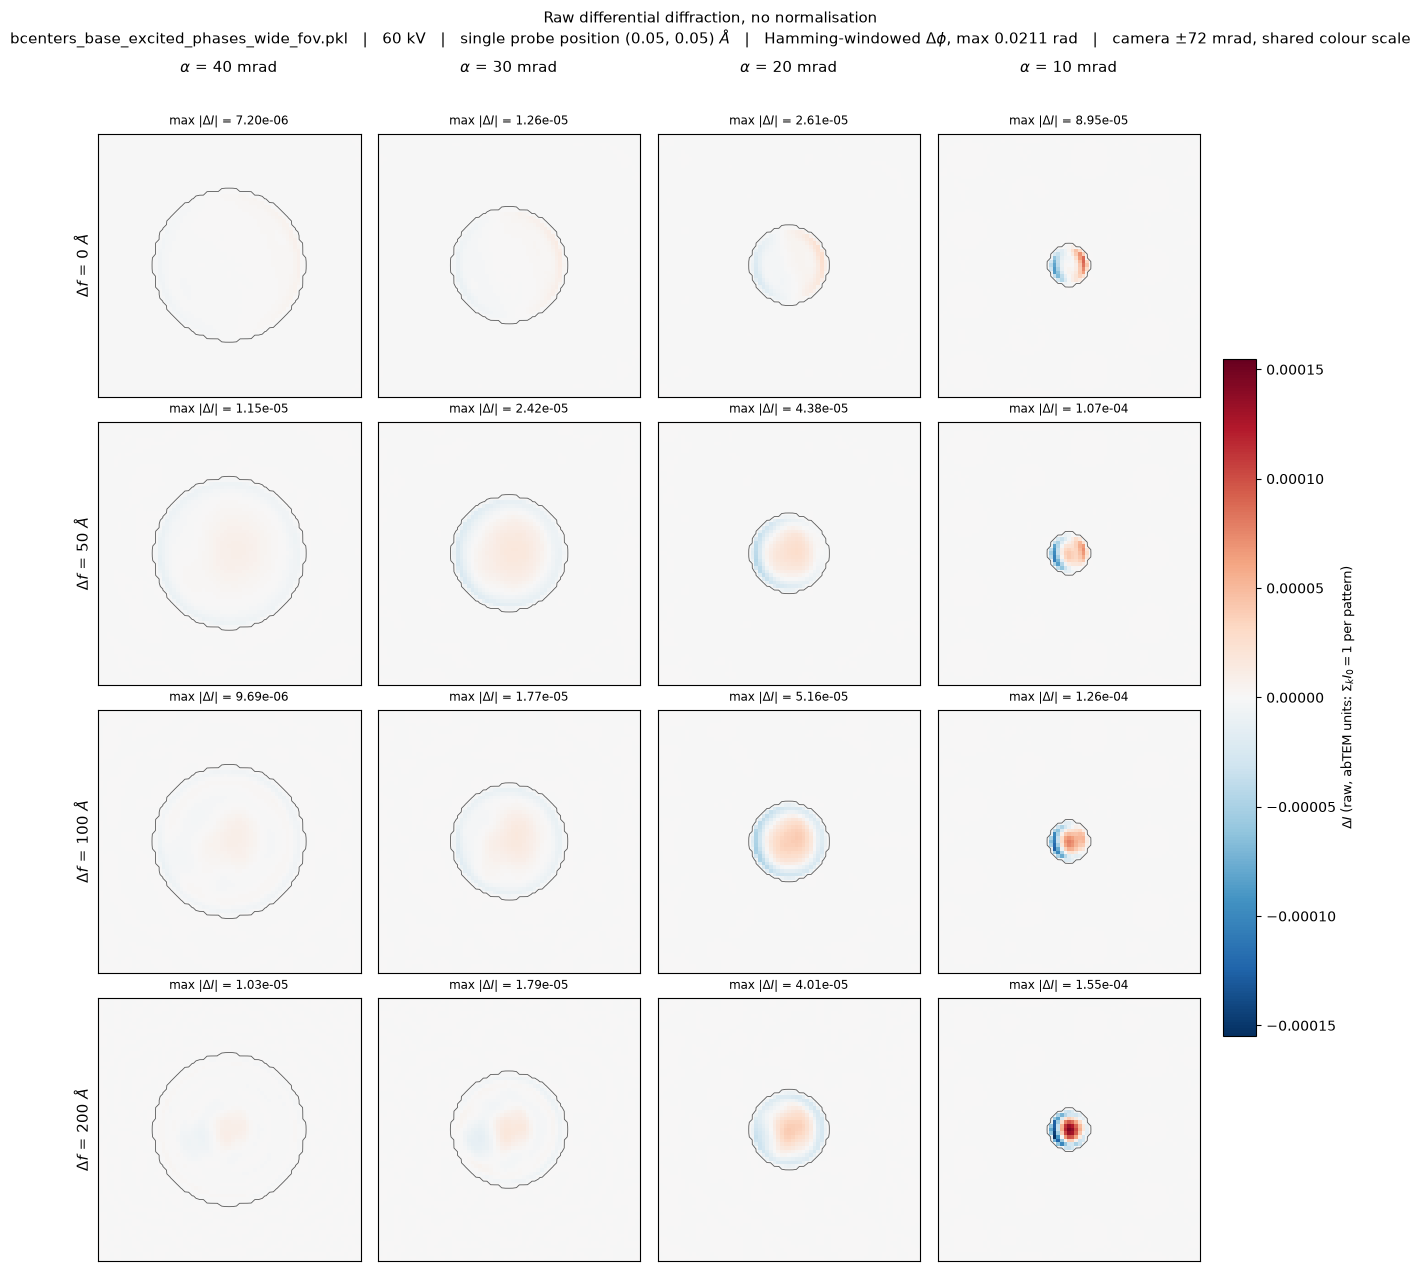

In [16]:
# Raw residual, no normalisation: dI = I_excited - I_base exactly as the forward model
# returns it. The only convention left is abTEM's, which normalises each diffraction
# pattern so that sum_k I_0 = 1 per scan position -- so these are fractions of one
# incident electron, not counts. One shared colour scale across all 16 panels, so the
# panels are directly comparable; each panel also prints its own max.

all_residuals = np.stack([residual_intensity_by_config[row, col]
                          for row in range(sweep_shape[0])
                          for col in range(sweep_shape[1])])
shared_limit = float(np.abs(all_residuals).max())
print("sum(I_0) per pattern      :", float(base_intensity_by_config[0, 0].sum()))
print("shared colour limit |dI|  :", f"{shared_limit:.4e}")
print("largest raw residual at   :",
      f"defocus {DEFOCUS_SWEEP_ANG[np.argmax(np.abs(all_residuals).max(axis=(1, 2))) // sweep_shape[1]]:.0f} A,",
      f"semiangle {SEMIANGLE_SWEEP_MRAD[np.argmax(np.abs(all_residuals).max(axis=(1, 2))) % sweep_shape[1]]:.0f} mrad")

fig, axes = plt.subplots(*sweep_shape, figsize=(13.0, 12.6), constrained_layout=True)
for row, defocus_ang in enumerate(DEFOCUS_SWEEP_ANG):
    for col, semiangle_mrad in enumerate(SEMIANGLE_SWEEP_MRAD):
        ax = axes[row, col]
        residual = residual_intensity_by_config[row, col]
        handle = ax.imshow(
            residual, cmap="RdBu_r", vmin=-shared_limit, vmax=shared_limit,
            interpolation="nearest", extent=detector_extent_mrad, origin="lower",
        )
        ax.contour(
            detector_axis_mrad, detector_axis_mrad, base_intensity_by_config[row, col],
            levels=[0.01 * base_intensity_by_config[row, col].max()],
            colors="0.35", linewidths=0.6,
        )
        ax.set_xlim(-DETECTOR_VIEW_HALFWIDTH_MRAD, DETECTOR_VIEW_HALFWIDTH_MRAD)
        ax.set_ylim(-DETECTOR_VIEW_HALFWIDTH_MRAD, DETECTOR_VIEW_HALFWIDTH_MRAD)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"max $|\Delta I|$ = {np.abs(residual).max():.2e}", fontsize=8.5)
        if row == 0:
            ax.text(0.5, 1.22, f"$\\alpha$ = {semiangle_mrad:.0f} mrad",
                    transform=ax.transAxes, ha="center", va="bottom", fontsize=11)
        if col == 0:
            ax.set_ylabel(f"$\\Delta f$ = {defocus_ang:.0f} $\\AA$", fontsize=11)

colour_bar = fig.colorbar(handle, ax=axes, shrink=0.6, pad=0.02)
colour_bar.set_label("$\\Delta I$ (raw, abTEM units: $\\Sigma_k I_0 = 1$ per pattern)",
                     fontsize=9)
fig.suptitle(
    f"Raw differential diffraction, no normalisation\n"
    f"{PHASE_CACHE_PATH.name}   |   {ACC_VOLTAGE_EV/1e3:.0f} kV   |   single probe "
    f"position ({probe_position_object_ang[0]:.2f}, {probe_position_object_ang[1]:.2f}) "
    f"$\\AA$   |   Hamming-windowed $\\Delta\\phi$, max {float(np.abs(excitation_phase_rad).max()):.4f} rad"
    f"   |   camera $\\pm${DETECTOR_VIEW_HALFWIDTH_MRAD:.0f} mrad, shared colour scale",
    fontsize=11,
)
plt.show()